# Huấn luyện trên GPU

GPU tính phép nhân ma trận nhanh hơn CPU nhiều lần, nên mạng neural thường được huấn luyện trên GPU. Bài này học cách đưa model và dữ liệu lên GPU, đo thời gian và bộ nhớ, và xử lý các lỗi hay gặp: hết bộ nhớ, loss thành NaN, bộ nhớ tăng dần vì giữ lại graph tính toán không cần. Cuối bài là cách ước lượng một lần huấn luyện mất bao lâu, để biết có chạy xong trong thời gian cho phép không.

> **Mục tiêu**
>
> - Kiểm code bằng cách cho model học thuộc một batch.
> - Tìm nguồn lỗi shape, dtype, device và NaN.
> - Ước lượng bộ nhớ; xử lý hết bộ nhớ bằng batch nhỏ, gradient accumulation, mixed precision.
> - Đo thời gian và bộ nhớ trên GPU.

## Chưa cần GPU để kiểm mạng biết học

Overfit một batch nghĩa là cố ý học lại một nhóm rất nhỏ nhiều lần. Với dữ liệu không có nhãn mâu thuẫn và mạng đủ capacity, train loss thường có thể giảm rất sâu. Nếu chưa làm được, đừng vội tăng dataset: có thể loss ghép sai, nhãn lệch mẫu, optimizer thiếu tham số hoặc graph bị cắt. Đây là kiểm sức khỏe pipeline, không phải điểm validation.

Ta dùng bốn góc của một hình vuông, nhãn theo dấu tọa độ thứ nhất. Tắt dropout, không augmentation để mục tiêu ổn định. Mạng nhỏ và seed cố định chạy CPU:

In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(31)
xb = torch.tensor([[-1., -1.], [-1., 1.], [1., -1.], [1., 1.]])
yb = torch.tensor([0, 0, 1, 1], dtype=torch.long)
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 2))
optimizer = torch.optim.Adam(model.parameters(), lr=.05)
criterion = nn.CrossEntropyLoss()
initial_loss = criterion(model(xb), yb).item()
for step in range(100):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    logits = model(xb)
    assert logits.shape == (4, 2)
    loss = criterion(logits, yb)
    assert torch.isfinite(loss)
    loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all()
               for p in model.parameters())
    optimizer.step()
model.eval()
with torch.no_grad():
    final_logits = model(xb)
    final_loss = criterion(final_logits, yb).item()
    accuracy = (final_logits.argmax(dim=1) == yb).float().mean().item()
print('loss:', round(initial_loss, 6), '->', round(final_loss, 6))
print('one-batch accuracy:', accuracy)

loss: 0.776305 -> 5.4e-05
one-batch accuracy: 1.0


Đọc loss đầu/cuối và accuracy trên **cùng bốn mẫu đã học**. Accuracy 1 ở đây chỉ xác nhận model có thể khớp nhóm nhỏ; nó không chứng minh khả năng dự đoán mẫu chưa thấy. Kiểm `grad is not None` thích hợp với mạng này vì mọi tham số tham gia forward. Model có nhánh điều kiện hoặc tham số đóng băng cần kiểm theo thiết kế, không bắt mọi tham số đều có gradient.



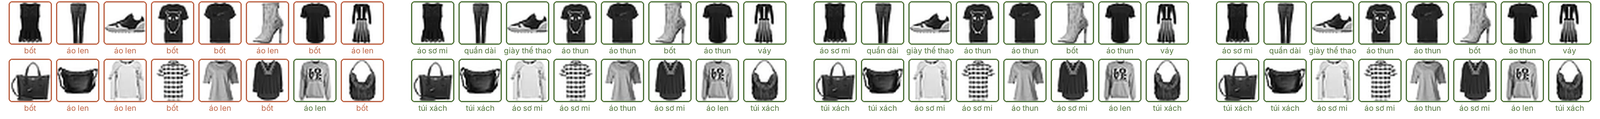

**Hỏi nhanh.** Sau 100 bước trên bốn mẫu, loss giảm từ 0.776 xuống 5.4e-05, và accuracy bằng 1.0. Ta kết luận được gì?

- A. Model sẽ đạt accuracy cao trên tập validation
- B. Có thể bỏ validation, vì loss đã gần bằng 0
- C. Forward, loss, backward và bước cập nhật đã được nối đúng
- D. Learning rate 0.05 cũng sẽ hợp với dữ liệu thật

<details><summary>Đáp án</summary>

C. Forward, loss, backward và bước cập nhật đã được nối đúng

Phép thử chỉ cho thấy cả quy trình đủ sức khớp bốn mẫu đã học: forward ra đúng shape, loss nhận đúng nhãn, gradient tới được tham số, và optimizer thật sự cập nhật. Nó không nói gì về những mẫu chưa thấy, nên vẫn cần validation. Learning rate hợp với bốn mẫu sạch chưa chắc hợp với một bộ dữ liệu lớn có nhiễu.

</details>

**Hỏi nhanh.** Thử cho model học thuộc 16 ảnh của một bài 10 lớp. Loss đứng yên ở 2.3026 suốt 200 bước, accuracy cũng không đổi. Nên kiểm gì trước?

- A. Thêm dữ liệu, vì 16 ảnh là quá ít để học
- B. Optimizer có nắm đúng tham số không, và có gọi `step()` không
- C. Tăng dropout để model bớt học thuộc batch
- D. Giảm batch xuống 1 cho gradient rõ hơn

<details><summary>Đáp án</summary>

B. Optimizer có nắm đúng tham số không, và có gọi `step()` không

$\ln 10 \approx 2.3026$ là cross-entropy khi model đoán đều cả 10 lớp, và con số không nhúc nhích nghĩa là tham số không đổi. Thủ phạm thường gặp: optimizer được tạo trên tham số của một model khác, hoặc tạo trước khi thay lớp cuối; quên `optimizer.step()`; learning rate bằng 0; hay graph bị cắt bởi `detach` hoặc `no_grad`. Thêm dữ liệu hay dropout không chữa được việc tham số không được cập nhật, và 16 ảnh là đủ cho phép thử này.

</details>

## Tìm lỗi theo điểm xuất hiện đầu tiên

Khi pipeline không học hoặc báo lỗi, ta lần ngược tới chỗ sai đầu tiên thay vì vá chỗ triệu chứng lộ ra:

- **Shape**: in shape của input, logits và target, gọi tên từng chiều (batch, lớp, đặc trưng) chứ không chỉ đếm số chiều.
- **Dtype**: target của cross-entropy là chỉ số lớp kiểu `long`, còn target của BCE là số thực.
- **Device**: model và mọi tensor đi vào cùng một phép phải nằm cùng nơi.
- **NaN**: kiểm lần lượt input, activation, logits, loss rồi gradient để tìm phép đầu tiên tạo giá trị không hữu hạn; `torch.isfinite` phát hiện cả NaN lẫn vô cùng. Một `nan` ở cuối có thể bắt đầu từ một phép chia cho 0 rất sớm.

Có thể bật `torch.autograd.detect_anomaly()` trên vài bước kiểm để thư viện hỗ trợ truy dấu backward; nó chậm nên không dùng trong mọi lượt đo.

Nếu loss hữu hạn nhưng gradient nổ, giảm learning rate chưa chắc chữa được phép đạo hàm không ổn định: kiểm log, chia và căn bậc hai tại miền không hợp lệ. `torch.where` vẫn lấy đạo hàm cả nhánh không được chọn: `torch.where(x > 0, x.sqrt(), 0)` với $x = -1$ có `sqrt(-1)` là NaN, và NaN nhân 0 trong backward vẫn là NaN; kẹp đầu vào trước khi lấy căn. Nếu gradient bằng `None`, kiểm `detach`/`no_grad` hoặc tham số chưa được dùng.

Để minh họa cách khoanh vùng mà không gây training nổ, ta kiểm một đầu vào lỗi:

In [ ]:
bad_input = torch.tensor([[1., float('nan')], [2., 3.]])
finite_rows = torch.isfinite(bad_input).all(dim=1)
print('finite rows:', finite_rows.tolist())
print('bad row indices:', (~finite_rows).nonzero(as_tuple=True)[0].tolist())

finite rows: [False, True]
bad row indices: [0]


Hàng đầu sai ngay từ input; đổi optimizer không sửa được dữ liệu ấy. Tùy bài, ta cần điều tra nguồn, điền thiếu bằng thống kê train hoặc loại dòng theo quy định dữ liệu; không tùy tiện thay mọi NaN thành 0 rồi coi pipeline đã đúng.

Lỗi device thường hiện ra ở dòng khác với chỗ gây ra nó. Model đã chuyển lên GPU, input cũng đã chuyển, nhưng một tensor khác tạo trong vòng lặp (target, mask, trọng số lớp) vẫn nằm ở CPU; phép đầu tiên chạm tới nó mới báo lỗi.



**Hỏi nhanh.** Đã gọi `model.to('cuda')` và `xb = xb.to('cuda')`. Forward chạy được, nhưng dòng `loss = criterion(logits, yb)` báo các tensor không nằm trên cùng thiết bị. Vì sao?

- A. Model mới lên GPU một phần, phải gọi lại `.to`
- B. `yb` vẫn ở CPU, phải chuyển nó sang cùng thiết bị
- C. Loss phải tính ở CPU, nên đưa logits về CPU
- D. `yb` phải đổi sang float cho khớp với logits

<details><summary>Đáp án</summary>

B. `yb` vẫn ở CPU, phải chuyển nó sang cùng thiết bị

Forward chạy được nghĩa là model và `xb` đã cùng nằm trên GPU, và phép đầu tiên chạm tới `yb` mới hỏng. Mọi tensor trong một phép tính, kể cả target và mask, phải cùng thiết bị. Đưa logits về CPU cũng chạy, nhưng mỗi bước lại phải chép dữ liệu qua lại. Đổi kiểu dữ liệu không sửa được lỗi thiết bị.

</details>

**Hỏi nhanh.** Logits có shape `(4, 3)`, target tạo bằng `torch.tensor([0., 2., 1., 1.])`. `nn.CrossEntropyLoss()` báo `expected scalar type Long but found Float`. Sửa thế nào?

- A. Đổi logits sang `.long()` cho cùng kiểu
- B. Đổi loss sang `BCEWithLogitsLoss`
- C. Tạo target kiểu `long`, chẳng hạn bằng `.long()`
- D. Đưa target về shape `(4, 3)` bằng `.view`

<details><summary>Đáp án</summary>

C. Tạo target kiểu `long`, chẳng hạn bằng `.long()`

Target là chỉ số lớp, nên phải là số nguyên kiểu `long`, shape `(4,)`. Ép logits về số nguyên thì mất luôn gradient. BCE dành cho nhãn nhị phân hoặc đa nhãn dạng float cùng shape với logits, không phải bài 3 lớp loại trừ nhau. `.view` không biến được 4 phần tử thành 12.

</details>

## Bộ nhớ có nhiều phần

Một tham số FP32 chiếm 4 byte. Training còn có gradient, và Adam giữ hai moment cùng thang FP32. Chỉ các phần này đã khoảng $4P+4P+8P=16P$ byte cho $P$ tham số, chưa tính activation, batch input và vùng nhớ tạm.

Đổi ra con số: 1 triệu tham số FP32 là 4 MB. Bảng embedding 100 000 từ, mỗi vector 300 chiều FP32, là 120 MB.

Activation phải giữ lại vì backward cần chúng (bài 3.2); suy luận không có backward nên dùng xong là bỏ. Mỗi ảnh tạo 1 triệu giá trị ở mỗi lớp, 50 lớp, batch 64, FP32 đã là $64 \cdot 50 \cdot 10^6 \cdot 4$ byte $\approx 12.8$ GB.

Gradient checkpointing chỉ lưu đầu ra của vài lớp rồi tính lại phần giữa khi backward, đổi thêm một lượt forward lấy bộ nhớ: 100 lớp chia 10 đoạn thì chỉ giữ cỡ 10 điểm lưu cộng 10 lớp của đoạn đang tính lại, thay vì 100.



In [ ]:
parameter_count = sum(p.numel() for p in model.parameters())
weight_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
print('parameters:', parameter_count)
print('weight bytes:', weight_bytes)
print('FP32 Adam parameter-state estimate:', 16 * parameter_count, 'bytes')
B, heads, L = 16, 8, 1024
score_bytes = B * heads * L * L * 4
print('materialized attention scores:', score_bytes // 2**20, 'MiB')

parameters: 42
weight bytes: 168
FP32 Adam parameter-state estimate: 672 bytes
materialized attention scores: 512 MiB


Mạng 42 tham số rất nhỏ, nhưng một tensor attention score (bài 3.9) giả định `(16,8,1024,1024)` FP32 đã là 512 MiB. Dòng đó chỉ **tính kích thước**, không cấp phát tensor ấy. Bình phương độ dài chính là $O(L^2)$ quen thuộc của thuật toán duyệt mọi cặp.

Kernel attention tối ưu (như FlashAttention) tính theo từng khối và không dựng toàn bộ bảng score, nên 512 MiB là chi phí của cách cài thẳng, không phải của mọi kernel.



**Hỏi nhanh.** Đổi Adam sang SGD có momentum, tức mỗi tham số giữ một buffer vận tốc, và vẫn dùng FP32. Phần weight, gradient và trạng thái optimizer còn khoảng bao nhiêu byte cho mỗi tham số?

- A. 4
- B. 8
- C. 12
- D. 16

<details><summary>Đáp án</summary>

C. 12

Weight 4 byte, gradient 4 byte, một buffer momentum 4 byte, tổng là 12. SGD không có momentum chỉ còn 8. 16 là của Adam, với hai moment. 4 là chỉ đếm weight. Activation là phần riêng, không đổi theo optimizer.

</details>

## Ví dụ tính tay: batch giảm thì phần nào giảm?

Với MLP, weight không đổi khi giảm batch 64 xuống 32; activation dạng `(B,h)` thường giảm khoảng một nửa. Gradient và optimizer state cũng không giảm vì số tham số giữ nguyên. Vì vậy đỉnh bộ nhớ GPU (VRAM) không giảm đúng một nửa.

Với attention dựng toàn bộ bảng score, giảm độ dài 1024 xuống 512 làm riêng score giảm bốn lần: tensor `(16,8,512,512)` FP32 chỉ còn $16\cdot8\cdot512^2\cdot4$ byte $= 128$ MiB thay vì 512 MiB, trong khi trọng số giữ nguyên.

**Hỏi nhanh.** Giảm batch size đi một nửa, giữ nguyên kiến trúc và optimizer. Phần bộ nhớ nào giảm theo, trong khi weights vẫn đứng yên?

- A. Input và activation của batch
- B. Mọi phần cùng giảm đúng một nửa
- C. Weights và hai moment của Adam
- D. Chỉ bộ nhớ đệm của allocator

<details><summary>Đáp án</summary>

A. Input và activation của batch

Input và activation tỉ lệ với số mẫu trong batch. Weights, gradient và moment tỉ lệ với số tham số, nên giữ nguyên. Bộ nhớ đệm của allocator và vùng làm việc của kernel cũng có thể đổi, nhưng không theo tỉ lệ cố định, nên tổng đỉnh bộ nhớ không giảm đúng một nửa.

</details>

## Hết bộ nhớ: microbatch và gradient accumulation

Lỗi `CUDA out of memory` (OOM) nghĩa là không xin được thêm vùng nhớ cho tensor kế tiếp. Cách sửa trực tiếp là giảm phần lớn nhất: batch, độ dài chuỗi, kích thước ảnh hoặc độ rộng mạng. `torch.cuda.empty_cache()` chỉ trả lại phần cache chưa được tensor nào dùng; nó không giải phóng tensor còn được tham chiếu.

Nguồn rò hay gặp là giữ tensor loss qua các step, như `history.append(loss)` hay `total = total + loss`: mỗi loss kéo theo graph của step đó. Nếu vòng validation vừa quên `torch.no_grad()` vừa giữ loss như vậy, backward không bao giờ chạy nên mỗi graph còn nguyên các activation đã lưu, và bộ nhớ tăng theo từng batch. Metric nên lưu bằng `loss.item()`. Sau khi sửa OOM, khởi động lại tiến trình để bỏ trạng thái cũ.

Giảm batch làm gradient nhiễu hơn và đổi động học huấn luyện. Muốn giữ batch hiệu dụng (effective batch) cũ, ta chia batch thành $k$ microbatch, gọi `backward()` cho từng microbatch và chỉ gọi `optimizer.step()` sau $k$ lần. PyTorch **cộng** gradient vào `.grad` qua các lần backward; loss mặc định lại là trung bình trong batch, nên mỗi loss microbatch phải chia cho $k$ thì tổng mới bằng gradient trung bình của cả batch. Thí nghiệm dưới so gradient của một batch 32 mẫu với bốn microbatch 8 mẫu, có và không chia loss:

In [ ]:
torch.manual_seed(7)
X_acc = torch.randn(32, 2)
y_acc = (X_acc[:, 0] > 0).long()
net = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 2))

def gradient_vector(module):
    return torch.cat([p.grad.flatten() for p in module.parameters()])

net.zero_grad(set_to_none=True)
criterion(net(X_acc), y_acc).backward()            # cả batch 32 mẫu một lần
full_grad = gradient_vector(net).clone()

accumulation_steps = 4
for divide_loss in (True, False):
    net.zero_grad(set_to_none=True)
    for x_part, y_part in zip(X_acc.chunk(accumulation_steps), y_acc.chunk(accumulation_steps)):
        micro_loss = criterion(net(x_part), y_part)  # mỗi microbatch 8 mẫu
        if divide_loss:
            micro_loss = micro_loss / accumulation_steps
        micro_loss.backward()                         # .grad cộng dồn qua các lần backward
    accumulated = gradient_vector(net)
    ratio = (accumulated.norm() / full_grad.norm()).item()
    print('divide by 4:', divide_loss, '| norm ratio:', round(ratio, 4),
          '| matches full batch:', torch.allclose(accumulated, full_grad, atol=1e-6))

divide by 4: True | norm ratio: 1.0 | matches full batch: True
divide by 4: False | norm ratio: 4.0 | matches full batch: False


Khi chia loss cho 4, gradient cộng dồn trùng gradient của batch 32 tới sai số làm tròn. Không chia, gradient lớn gấp đúng 4 lần: với SGD, điều đó tương đương lặng lẽ nhân learning rate với 4. Phép trùng cần hai điều kiện:

- Các microbatch phải bằng nhau; microbatch cuối thiếu mẫu thì phải chia theo số mẫu thật.
- Mạng không có lớp tính thống kê theo batch: BatchNorm chuẩn hóa theo từng microbatch 8 mẫu, nên accumulation không tái tạo được thống kê của batch 32.

Bộ nhớ activation chỉ còn cỡ một microbatch, còn weight, gradient và trạng thái optimizer giữ nguyên. Mỗi optimizer step tốn $k$ lượt forward/backward nối tiếp, nên accumulation tiết kiệm bộ nhớ chứ không tăng tốc. Số lần cập nhật chia cho $k$: 50 000 mẫu, batch 128 có 390 batch đủ mỗi epoch, 10 epoch với $k = 4$ cho 975 lần step.



**Hỏi nhanh.** Batch 64 bị OOM, batch 16 thì chạy được. Ta dùng accumulation 4 microbatch, mỗi microbatch 16 mẫu, trên 6400 mẫu train. Mỗi epoch có bao nhiêu lần `backward()` và bao nhiêu lần `optimizer.step()`?

- A. 100 lần backward, 100 lần step
- B. 400 lần backward, 400 lần step
- C. 100 lần backward, 400 lần step
- D. 400 lần backward, 100 lần step

<details><summary>Đáp án</summary>

D. 400 lần backward, 100 lần step

Mỗi microbatch 16 mẫu gọi backward một lần, nên có $6400/16 = 400$ lần. Optimizer chỉ bước sau mỗi 4 microbatch, nên có $400/4 = 100$ lần, đúng bằng số bước của batch 64. Khi loss đã chia cho 4 và mạng không có BatchNorm, mỗi bước giống hệt một bước với batch 64, nên dùng lại được learning rate của cấu hình batch 64.

</details>

## Mixed precision là lựa chọn số học

Mixed precision dùng kiểu số ít bit hơn (FP16, 2 byte) cho những phép chịu được và giữ những phép nhạy ở FP32. `autocast` chọn dtype theo từng phép: nhân ma trận và convolution chạy FP16, còn softmax, log, exp, phép tổng và phần lớn hàm loss giữ FP32. Model không bị ép toàn bộ thành FP16, và bản trọng số mà optimizer cập nhật vẫn là FP32.

Lợi ích là nhiều activation chỉ còn 2 byte thay vì 4, và Tensor Core của GPU chạy phép FP16 nhanh hơn nhiều. Cái giá là FP16 chỉ biểu diễn được một khoảng số hẹp.

Gradient ở nhiều lớp rất nhỏ. FP16 không biểu diễn được số dương nhỏ hơn khoảng $6\cdot10^{-8}$, nên một gradient cỡ $10^{-8}$ bị làm tròn về 0. GradScaler nhân loss với một hệ số lớn (mặc định khởi đầu $2^{16} = 65\,536$) trước backward; theo quy tắc chuỗi, mọi gradient cũng được nhân theo, rồi được chia lại trước khi optimizer cập nhật. Phép thử trên CPU cho thấy cơ chế:

In [ ]:
tiny_grad = torch.tensor(1e-8)
scale = 65536.0
print('FP16 of 1e-8:', tiny_grad.half().item())
scaled_half = (tiny_grad * scale).half()
print('FP16 of 1e-8 * 65536:', round(scaled_half.item(), 8))
print('unscaled in FP32:', f'{scaled_half.float().item() / scale:.4e}')

FP16 of 1e-8: 0.0
FP16 of 1e-8 * 65536: 0.00065517
unscaled in FP32: 9.9972e-09


Đưa thẳng $10^{-8}$ vào FP16 cho 0: gradient ấy mất hẳn. Nhân 65536 trước thì được $6.55\cdot10^{-4}$, nằm gọn trong khoảng của FP16; chia lại ở FP32 cho $9.9972\cdot10^{-9}$, lệch khoảng 0.03% vì FP16 chỉ giữ được khoảng ba chữ số có nghĩa. Nếu hệ số lớn quá làm gradient tràn thành inf hoặc NaN, `scaler.step` bỏ qua bước đó và `scaler.update()` giảm hệ số; sau một chuỗi bước ổn định, hệ số được tăng lại. GradScaler không chữa được nhãn sai hay learning rate quá lớn.

Bản trọng số FP32 cũng cần vì một lý do tương tự: cập nhật thường nhỏ hơn trọng số rất nhiều, và trong FP16 phép cộng $1 + 10^{-4}$ làm tròn về đúng 1, nên cập nhật sẽ mất nếu cộng thẳng vào bản 16 bit.

BF16 có cùng khoảng số mũ với FP32 nên thường không cần scaler, nhưng chỉ chạy nhanh trên GPU từ thế hệ Ampere trở đi; với T4, mixed precision nghĩa là FP16 kèm GradScaler.



**Hỏi nhanh.** GradScaler nhân loss với 65536 trước khi backward. Vì sao bước cập nhật không lớn gấp 65536 lần?

- A. Gradient được chia lại trước khi cập nhật
- B. Learning rate cũng tự chia cho 65536
- C. FP16 tự làm tròn gradient về giá trị thật
- D. Hệ số chỉ nhân vào con số loss in ra log

<details><summary>Đáp án</summary>

A. Gradient được chia lại trước khi cập nhật

`scaler.step`, hoặc `unscale_` gọi trước đó, chia gradient cho đúng hệ số rồi mới để optimizer dùng, nên bước cập nhật giống như khi không nhân. Hệ số này chỉ giúp những gradient nhỏ không bị làm tròn về 0 trong lúc backward. Learning rate không bị đụng tới. Hệ số tác động thật lên backward, chứ không chỉ lên con số in ra.

</details>

Thứ tự một step trong script: autocast cho forward và loss → `scaler.scale(loss).backward()` → `scaler.unscale_(optimizer)` → clip nếu cần → `scaler.step(optimizer)` → `scaler.update()`. Clip phải đứng sau `unscale_`: trước đó norm gradient còn lớn gấp hệ số scale, nên ngưỡng clip 1.0 gần như luôn bị kích hoạt và sau khi chia lại, gradient bị thu nhỏ quá mức. Script dùng API `torch.amp` theo tài liệu PyTorch 2.9; mã cũ hơn viết `torch.cuda.amp`.

## Đo trên máy có GPU

Phần đo tốc độ nằm trong script [gpu_probe.py](recipes/gpu_probe.py), chạy riêng trên máy có GPU. Script tự tạo một MLP 512→256→10 với AdamW và một batch ngẫu nhiên ngay trên GPU, nên không cần tải dữ liệu hay model. Lệnh đầu chỉ kiểm môi trường: in phiên bản PyTorch, bản CUDA mà PyTorch được build kèm và trạng thái `CUDA_READY` hoặc `CPU_ONLY`. Hai lệnh sau chạy benchmark ở FP32 và ở mixed precision:

```text
python content/phase-3/recipes/gpu_probe.py
python content/phase-3/recipes/gpu_probe.py --run --precision fp32
python content/phase-3/recipes/gpu_probe.py --run --precision amp
```

Benchmark cần GPU CUDA hoạt động và bản PyTorch tương thích. Trên máy chỉ có CPU, script dừng với `CUDA_NOT_AVAILABLE`; khi hết bộ nhớ, nó dừng với `CUDA_OOM` và gợi ý giảm `--batch`. Mỗi lượt chạy 5 step warmup, đồng bộ, đặt lại bộ đếm peak memory, đo 50 step (đổi bằng `--warmup`, `--steps`) rồi đồng bộ lần nữa.

Kết quả là một dòng JSON gồm:

- `device`: tên GPU;
- `milliseconds_per_step`, `samples_per_second` (batch × số step chia thời gian);
- `peak_allocated_MiB`: bộ nhớ tensor dùng lúc cao nhất;
- `peak_reserved_MiB`: phần PyTorch giữ, thường lớn hơn vì có cache.

So hai dòng FP32 và AMP cùng batch để thấy mixed precision tiết kiệm bao nhiêu thời gian và bộ nhớ trên đúng card đó. Nếu môi trường thi cấp T4, chạy chính phép đo ấy trên T4: số giây không suy ra được từ tên card. Phần đo chỉ gồm loop training trên batch đã ở GPU (`includes_data_loading: false`); nếu đọc ảnh hay chép CPU→GPU mới là nút thắt, phải đo riêng pipeline đầy đủ.

CUDA chạy bất đồng bộ: CPU xếp lệnh vào hàng đợi rồi đi tiếp ngay, nên đồng hồ CPU đọc lúc ấy chỉ đo việc gửi lệnh dù GPU chưa làm xong. Đồng bộ trước và sau đoạn đo, hoặc dùng CUDA events, mới đo được công việc thực. Không gọi `.item()` ở mỗi batch trong benchmark nếu không cần, vì lấy số về CPU buộc phải đồng bộ và làm thay đổi chính thứ đang đo.

GPU nhanh nhờ chạy song song hàng nghìn phép trên tensor lớn. Mạng 42 tham số với batch 4 ở đầu bài thì ngược lại: mỗi step chỉ vài trăm phép nhân, còn chi phí khởi chạy kernel, chép dữ liệu và đồng bộ là cố định, nên trên GPU nó có thể chậm hơn trên CPU.

**Hỏi nhanh.** Đo thời gian chạy CUDA bằng `time.perf_counter()` của CPU mà không synchronize. Con số đo được có thể phản ánh điều gì?

- A. Thời gian GPU thực sự chạy hết các kernel
- B. Thời gian chép dữ liệu từ ổ đĩa lên GPU
- C. Thời gian đã tự trừ đi các bước khởi động
- D. Phần lớn chỉ là thời gian CPU gửi lệnh đi

<details><summary>Đáp án</summary>

D. Phần lớn chỉ là thời gian CPU gửi lệnh đi

Lệnh CUDA được xếp vào hàng đợi, và CPU chạy tiếp ngay. Không đồng bộ ở cuối thì đồng hồ dừng khi GPU có thể còn đang làm, nên số đo nhỏ bất thường. Đọc ổ đĩa không nằm trong đoạn này. Các bước khởi động phải tự chạy trước khi bấm giờ, đồng hồ không tự trừ.

</details>

## Ước lượng thời gian chạy

Gọi $t$ là median step time đo trên những batch đại diện. Với $N$ mẫu, batch $B$ và $E$ epoch, phần train xấp xỉ

$$T_{\text{train}} \approx E\left\lceil \frac{N}{B} \right\rceil t.$$

Lấy median sau warmup, vì vài step đầu chậm do khởi tạo kernel và allocator. Chẳng hạn $N = 50\,000$, $B = 128$ cho $\lceil 390.6 \rceil = 391$ step mỗi epoch; nếu đo được $t = 0.12$ giây thì 20 epoch tốn $20 \cdot 391 \cdot 0.12 \approx 938$ giây, khoảng 15.6 phút. Đó mới là phần train: còn validation, đọc dữ liệu, lưu checkpoint và thời gian khởi động.

Batch tăng thông lượng chứ không giảm độ trễ: một batch 32 ảnh mất 0.4 giây là 80 ảnh mỗi giây, gấp 4 lần chạy từng ảnh 0.05 giây, nhưng ảnh nào cũng phải chờ cả batch xong. $t$ phải đo với shape giống dữ liệu thật trên đúng phần cứng được cấp; số đo của mạng rất nhỏ không dùng để suy ra cho model pretrained lớn.



**Hỏi nhanh.** Tiếp ví dụ trên, với $t$ đã đo trên chính máy được cấp: phần train mất khoảng 15.6 phút, ngân sách là 20 phút, và mỗi epoch còn có validation đo được 15 giây. Kế hoạch 20 epoch có vừa không?

- A. Vừa, còn dư hơn 4 phút cho phần khác
- B. Vừa, vì validation dùng `no_grad` nên gần như không tốn
- C. Không vừa, cộng validation vào đã khoảng 20.6 phút
- D. Chưa biết được, phải đo lại $t$ trên T4

<details><summary>Đáp án</summary>

C. Không vừa, cộng validation vào đã khoảng 20.6 phút

Validation mất $20 \times 15$ giây, tức 5 phút. Cộng với 15.6 phút train là 20.6 phút, vượt ngân sách trước cả khi tính thời gian đọc dữ liệu và lưu checkpoint. `no_grad` bỏ được backward và tiết kiệm bộ nhớ, nhưng forward trên tập validation vẫn tốn thời gian. $t$ đã đo trên máy được cấp, nên không cần đo lại. Cần giảm số epoch, validate thưa hơn, hoặc rút ngắn mỗi bước.

</details>

## Khi đi thi

- **Kiểm một batch trước khi chạy dài.** Overfit 4–16 mẫu, assert shape và `torch.isfinite` cho loss, gradient; lỗi bắt ở đây rẻ hơn nhiều so với lỗi lộ ra sau một giờ GPU.
- **Đọc môi trường ở ô đầu tiên.** In `torch.cuda.is_available()`, tên GPU và phiên bản PyTorch; đọc luật về giờ GPU, Internet và thư viện của đề trước khi chọn model.
- **Quy ngân sách ra số step.** Đo median $t$ sau warmup, tính $E\lceil N/B\rceil t$, cộng validation, I/O, checkpoint và để dư cho một lần chạy lại.
- **OOM: sửa có thứ tự.** Giảm batch hoặc độ dài, bật mixed precision, dùng accumulation với loss chia $k$; khởi động lại tiến trình sau khi sửa. Model có BatchNorm thì microbatch nhỏ làm đổi thống kê.
- **Lưu sớm, lưu thường xuyên.** Phiên GPU có thể bị ngắt khi hết giờ: ghi `state_dict` mỗi epoch và tạo file submission từ checkpoint tốt nhất ngay khi có.

## Tóm tắt

- Kiểm khả năng học trước (học thuộc một batch), đo tốc độ sau.
- Tìm lỗi từ nơi xuất hiện đầu tiên: shape, dtype, device, NaN.
- Bộ nhớ GPU gồm trọng số, gradient, trạng thái optimizer, activation và phần tạm; giảm batch chỉ giảm phần activation.
- Gradient accumulation giữ batch hiệu dụng khi loss mỗi microbatch được chia $k$; tiết kiệm bộ nhớ, không tăng tốc.
- Mixed precision cần autocast và GradScaler đúng thứ tự, unscale trước khi clip.
- Thời gian chạy phải đo trên đúng phần cứng được cấp.

## Kiểm tra cuối bài

**Câu 1.** Training ổn định suốt 22 epoch, sang epoch 23 thì loss đột ngột thành NaN. Muốn tìm ra nguyên nhân thay vì đoán, cách nào chặt chẽ nhất?

- A. Giảm learning rate 10 lần, thêm clip, chuyển sang AMP
- B. Bật anomaly detection, ghi log activation, và xem batch gây lỗi
- C. Cộng epsilon vào mọi mẫu số rồi train lại từ epoch 1
- D. Thay BatchNorm bằng LayerNorm, và thu nhỏ model

<details><summary>Đáp án</summary>

B. Bật anomaly detection, ghi log activation, và xem batch gây lỗi

Lỗi xuất hiện muộn sau một giai đoạn ổn định, nên cần bằng chứng. Phép nào tạo ra giá trị không hữu hạn đầu tiên? Activation có lớn dần không? Batch ấy có dữ liệu lạ không? Ba cách còn lại đều là sửa mù, có thể che triệu chứng mà không biết nguyên nhân. FP16 với khoảng số hẹp còn dễ tràn hơn. Khi đã khoanh vùng được, chẳng hạn một phép chia cho 0 trong loss, thì epsilon hay clip mới là cách sửa có căn cứ.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 283](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=107)

</details>

**Câu 2.** Vòng validation không bọc trong `torch.no_grad()`, và chạy `val_losses.append(loss)` sau mỗi batch. VRAM tăng dần qua các batch validation, rồi OOM. Sửa thế nào cho đúng gốc?

- A. Bọc vòng lặp trong `torch.no_grad()`, và lưu `loss.item()`
- B. Gọi `torch.cuda.empty_cache()` sau mỗi batch validation
- C. Gọi `model.eval()` trước vòng validation là đủ
- D. Giảm batch validation một nửa, giữ nguyên code

<details><summary>Đáp án</summary>

A. Bọc vòng lặp trong `torch.no_grad()`, và lưu `loss.item()`

Không có `no_grad`, mỗi loss mang theo graph và các activation đã lưu để backward. Backward không bao giờ chạy để giải phóng chúng, và list vẫn giữ tham chiếu, nên bộ nhớ tăng theo từng batch. `empty_cache` chỉ trả lại phần bộ nhớ đệm không chứa tensor nào còn sống. `model.eval()` đổi cách hoạt động của dropout và BatchNorm, không tắt autograd. Giảm batch chỉ làm OOM đến muộn hơn.

</details>

**Câu 3.** Fine-tune một mô hình ngôn ngữ BERT 110 triệu tham số bằng AdamW FP32 trên GPU 16 GB. Batch 32 với chuỗi dài 512 bị OOM. Phần weight, gradient và hai moment chiếm khoảng bao nhiêu, và phần còn lại chủ yếu là gì?

- A. Khoảng 0.44 GB, phần còn lại chủ yếu là activation
- B. Khoảng 0.44 GB, OOM là do số tham số quá lớn
- C. Khoảng 1.76 GB, OOM là do số tham số quá lớn
- D. Khoảng 1.76 GB, phần còn lại chủ yếu là activation

<details><summary>Đáp án</summary>

D. Khoảng 1.76 GB, phần còn lại chủ yếu là activation

$16 \times 1.1\cdot 10^8 = 1.76\cdot 10^9$ byte. 0.44 GB chỉ là weight, quên gradient và hai moment. Phần theo tham số chưa tới 2 GB trên 16 GB, nên phần lớn còn lại là activation, tăng theo batch và độ dài chuỗi, cộng với vùng làm việc của kernel. Giảm batch, giảm độ dài, dùng accumulation hay mixed precision là nhắm đúng phần này. Đổi sang model nhỏ hơn không phải bước đầu tiên.

</details>

**Câu 4.** Train một mạng phân loại ảnh ResNet-50 với batch 128 trên GPU 16 GB có Tensor Core cho FP16 thì OOM, dù chỉ vượt bộ nhớ một chút. Cách nào cân bằng tốt nhất giữa bộ nhớ và tốc độ?

- A. Accumulation 4 microbatch × 32, kèm gradient checkpointing
- B. Mixed precision FP16, kèm loss scaling động
- C. Giảm batch còn 32, chấp nhận gradient nhiễu hơn
- D. Gọi `empty_cache()` sau mỗi backward, và bật `pin_memory`

<details><summary>Đáp án</summary>

B. Mixed precision FP16, kèm loss scaling động

Mixed precision làm nhiều activation chỉ còn một nửa kích thước, và trên Tensor Core còn chạy nhanh hơn, nên vừa hết OOM vừa tăng tốc. Accumulation kèm checkpointing chắc chắn vừa bộ nhớ, nhưng phải tính lại activation và chạy 4 lượt nối tiếp, nên chậm hơn. Giảm batch làm đổi cách mô hình học mà không tăng tốc. `empty_cache` không giải phóng tensor còn sống, còn `pin_memory` chỉ tăng tốc việc chép dữ liệu.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 285](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=108)

</details>

**Câu 5.** Fine-tune BERT 110 triệu tham số trên GPU 16 GB. Batch 32 bị OOM, còn batch 8 vừa bộ nhớ nhưng training dao động. Ta dùng gradient accumulation với `accumulation_steps=4`. Kết quả là gì?

- A. Nhanh gấp 4, vì bốn microbatch được tính song song
- B. Bộ nhớ giảm 75%, vì gradient bị bỏ sau mỗi microbatch
- C. Accuracy tăng, vì nhiễu gradient đóng vai trò regularization
- D. Batch hiệu dụng là 32, còn activation chỉ cần cho 8 mẫu

<details><summary>Đáp án</summary>

D. Batch hiệu dụng là 32, còn activation chỉ cần cho 8 mẫu

Gradient của bốn microbatch 8 mẫu được cộng lại, sau khi loss đã chia cho 4, rồi mới cập nhật. Vì vậy mỗi bước dùng gradient trung bình của 32 mẫu, còn activation chỉ cần cho 8 mẫu một lúc. Các microbatch chạy nối tiếp nên không nhanh hơn. Gradient được giữ lại để cộng, chứ không bị bỏ. Batch hiệu dụng lớn hơn làm gradient bớt nhiễu, ngược với lập luận về regularization.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 296](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=113)

</details>

**Câu 6.** Vòng gradient accumulation:

```py
accumulation_steps = 4
optimizer.zero_grad()
for i, (inputs, targets) in enumerate(loader):
    loss = criterion(model(inputs), targets)
    loss = loss / accumulation_steps      # dòng A
    loss.backward()
    if (i + 1) % accumulation_steps == 0:
        optimizer.step()
        optimizer.zero_grad()
```

Vì sao cần dòng A?

- A. Để gradient cộng dồn bằng đúng gradient của cả batch lớn
- B. Để tránh tràn số khi gọi backward nhiều lần liên tiếp
- C. Không bắt buộc, dòng A chỉ đổi con số loss in ra log
- D. Để bù cho thống kê BatchNorm vốn tính trên microbatch nhỏ

<details><summary>Đáp án</summary>

A. Để gradient cộng dồn bằng đúng gradient của cả batch lớn

`criterion` trả về trung bình trong một microbatch, còn `.grad` cộng dồn qua bốn lần backward. Thiếu dòng A thì gradient lớn gấp 4 so với train thật bằng batch gấp 4, giống như lặng lẽ nhân learning rate với 4. Bốn phép cộng trong FP32 không gây tràn số. Dòng A đổi chính gradient, không chỉ con số in ra. BatchNorm vẫn chuẩn hóa theo microbatch, và chia loss không sửa được điều đó.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 11](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=16)

</details>

**Câu 7.** Ba cách viết một bước mixed precision, sau khi đã tính `loss` trong `autocast`:

```py
# Cách A
loss.backward(); optimizer.step()
# Cách B
scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
# Cách C
scaler.scale(loss).backward()
scaler.unscale_(optimizer)
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
scaler.step(optimizer); scaler.update()
```

Cách A làm training hỏng, cách B chạy tốt. Khi nào phải dùng cách C thay cho B?

- A. Khi mạng rất sâu, để chống gradient bùng nổ
- B. Khi có clip gradient, để ngưỡng clip đúng nghĩa
- C. Khi batch rất nhỏ làm gradient dao động mạnh
- D. Chỉ khi debug, để in ra độ lớn gradient thật

<details><summary>Đáp án</summary>

B. Khi có clip gradient, để ngưỡng clip đúng nghĩa

`unscale_` chia gradient cho hệ số scale trước khi clip. Nếu clip ngay sau backward, độ lớn đo được còn lớn gấp hệ số scale, và ngưỡng 1.0 mất nghĩa. Mạng sâu hay batch nhỏ chỉ là lý do để cân nhắc có clip hay không; đã clip thì luôn phải unscale trước. `scaler.step` tự unscale nếu chưa gọi, nên không clip thì cách B là đủ. Việc in gradient cũng không bắt buộc phải theo cách C.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 16](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=24)

</details>

**Câu 8.** Chuyển đúng mạng $2 \to 8 \to 2$ ở đầu bài, batch 4 mẫu, sang GPU. Mỗi bước lại chậm hơn trên CPU. Lý do hợp lý nhất là gì?

- A. Việc quá nhỏ, nên chi phí gọi kernel và chép dữ liệu lấn át
- B. GPU chỉ nhanh hơn CPU khi đã bật mixed precision
- C. Adam phải chép hai moment về CPU sau mỗi bước
- D. Batch 4 không chia hết cho số lõi tính của GPU

<details><summary>Đáp án</summary>

A. Việc quá nhỏ, nên chi phí gọi kernel và chép dữ liệu lấn át

GPU nhanh khi có rất nhiều phép tính song song trên tensor lớn. Một bước của mạng 42 tham số chỉ có vài trăm phép nhân, nên thời gian gần như toàn là chi phí cố định: khởi chạy kernel, chép batch từ CPU lên GPU, đồng bộ khi gọi `.item()`. Tăng batch hoặc kích thước model thì mới thấy lợi thế. FP32 trên GPU vẫn nhanh với việc đủ lớn. Moment của Adam nằm sẵn trên GPU. GPU cũng không đòi batch phải chia hết cho số lõi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 144](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=54)

</details>

**Câu 9.** Giả sử chạy `gpu_probe.py --run --batch 128`, và dòng JSON báo `milliseconds_per_step` bằng 25. Thông lượng là bao nhiêu, và con số ấy đã tính cả việc đọc dữ liệu chưa?

- A. 3200 mẫu mỗi giây, đã tính cả đọc dữ liệu
- B. 3200 mẫu mỗi giây, chưa tính đọc dữ liệu
- C. 5120 mẫu mỗi giây, chưa tính đọc dữ liệu
- D. 5120 mẫu mỗi giây, đã tính cả đọc dữ liệu

<details><summary>Đáp án</summary>

C. 5120 mẫu mỗi giây, chưa tính đọc dữ liệu

Mỗi bước xử lý 128 mẫu trong 0.025 giây, nên thông lượng là $128/0.025 = 5120$ mẫu mỗi giây. 3200 là $128 \times 25$, nhầm mili giây với giây. Script chỉ đo vòng train trên batch đã nằm sẵn trên GPU (`includes_data_loading: false`), nên khi chạy thật, có thêm đọc ảnh và chép từ CPU lên GPU, có thể chậm hơn.

</details>

**Câu 10.** Ngân sách 140 giờ GPU, và ResNet-50 cần 90 epoch để hội tụ. Số đo sau 90 epoch: batch 256 đạt top-1 76.5%, mỗi epoch 8 giờ. Batch 2048, dùng optimizer LARS cho batch lớn và warmup 5 epoch, đạt 75.8%, mỗi epoch 1.5 giờ. Batch 8192 đạt 73.2%, mỗi epoch 0.5 giờ. Chọn cách nào để accuracy cao nhất trong ngân sách?

- A. Batch 256, chạy tới khi hết ngân sách
- B. Batch 8192 đủ 90 epoch, chỉ hết 45 giờ
- C. Accumulation 4 × 2048, vừa có tốc độ của 8192 vừa có chất lượng của 2048
- D. Batch 2048 với LARS và warmup, chạy đủ 90 epoch

<details><summary>Đáp án</summary>

D. Batch 2048 với LARS và warmup, chạy đủ 90 epoch

Batch 256 cần $90 \cdot 8 = 720$ giờ, mà 140 giờ chỉ đủ 17.5 epoch, chưa hội tụ nên không đạt được 76.5%. Batch 2048 tốn $90 \cdot 1.5 = 135$ giờ, vừa ngân sách, và đạt 75.8%. Batch 8192 nhanh nhất nhưng accuracy thấp hơn rõ. Accumulation 4 × 2048 cập nhật như batch 8192, tức ít bước, mỗi bước trung bình 8192 mẫu, mà mỗi epoch vẫn tốn cỡ thời gian của batch 2048, ngược với điều phương án ấy hứa.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 295](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=113)

</details>

## Đọc thêm

- [PyTorch 2.9 — CUDA semantics](https://docs.pytorch.org/docs/2.9/notes/cuda.html): đọc bất đồng bộ, synchronize, allocator và phép đo thời gian.
- [PyTorch 2.9 — AMP](https://docs.pytorch.org/docs/2.9/amp.html): tra autocast, GradScaler và dtype theo phép.
- [PyTorch — AMP examples](https://docs.pytorch.org/docs/2.9/notes/amp_examples.html): đọc gradient clipping sau unscale và accumulation đúng.

Nguồn ảnh: ảnh quần áo lấy từ bộ Fashion-MNIST của Zalando (giấy phép MIT).